In [54]:
import pandas as pd 
import matplotlib.pyplot as plt 
import numpy as np 
import seaborn as sns 
import matplotlib.patches as mpatches
import matplotlib.lines as mlines



data_salary = pd.read_csv("../datasets/raw/salaries.csv")



: 

In [55]:
data_salary.describe()

,work_year,salary,salary_in_usd,remote_ratio
count,73148.000000,7.314800e+04,73148.000000,73148.000000
mean,2023.831192,1.625534e+05,158013.748619,21.582955
std,0.477551,1.925761e+05,72501.304728,41.023051
min,2020.000000,1.400000e+04,15000.000000,0.000000
25%,2024.000000,1.069575e+05,106890.000000,0.000000
50%,2024.000000,1.480000e+05,147500.000000,0.000000
75%,2024.000000,2.000000e+05,199700.000000,0.000000
max,2025.000000,3.040000e+07,800000.000000,100.000000


In [56]:
dic_experience_level={
    "EN":"Junior",
    "MI":"Intermediate",
    "SE":"Expert",
    "EX":"Director",
}

dic_employment_type = {
    "PT":"Part-time",
    "FT":"Full-time",
    "CT":"Contract",
    "FL":"Freelance",
}

dic_remote_ratio = {
    "0":"No remote work (less than 20%)",
    "50":"Partially remote",
    "100":"Fully remote (more than 80%)",    
}

dic_company_size = {
    "S":"less than 50 employees (small)",
    "M":"50 to 250 employees (medium)",
    "L":"more than 250 employees (large)",
}



📊 1. Tendances Générales des Salaires

1.a. Ecart entre salaire bas et élévé

In [57]:
print(f"min: {data_salary['salary_in_usd'].min()}")
print(f"max: {data_salary['salary_in_usd'].max()}")




min: 15000
max: 800000


Etude écart par experience_level

C:\Users\Angelo Morningstar\AppData\Local\Temp\ipykernel_13972\1925624043.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=data_salary["experience_level"], y=data_salary["salary_in_usd"], palette=colors)


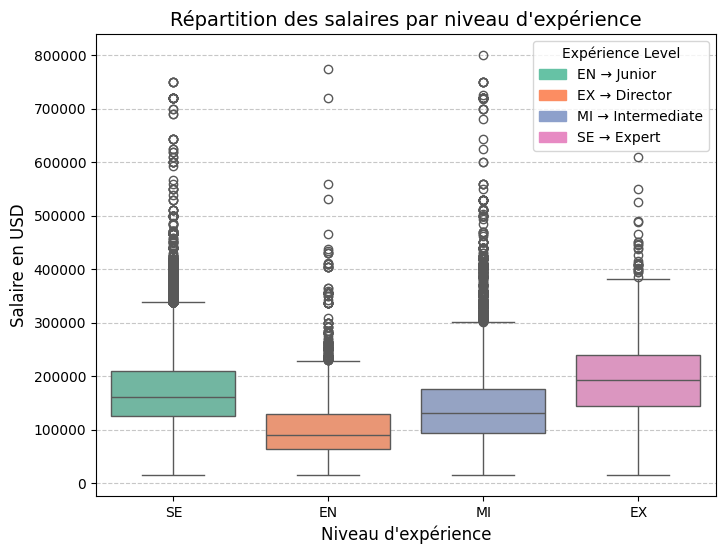

In [58]:
plt.figure(figsize=(8, 6))

# Liste des catégories uniques dans l'ordre
unique_experience_level = sorted(data_salary["experience_level"].unique())

# Palette de couleurs utilisée par sns.boxplot
colors = sns.color_palette("Set2", len(unique_experience_level))

sns.boxplot(x=data_salary["experience_level"], y=data_salary["salary_in_usd"], palette=colors)

plt.title("Répartition des salaires par niveau d'expérience", fontsize=14)
plt.xlabel("Niveau d'expérience", fontsize=12)
plt.ylabel("Salaire en USD", fontsize=12)
plt.grid(axis='y', linestyle="--", alpha=0.7)


# Créer la légende avec les vraies couleurs (conversion en str)
legend_patches = [
    mpatches.Patch(color=colors[i], label=f"{str(key)} → {dic_experience_level[str(key)]}")
    for i, key in enumerate(unique_experience_level) if str(key) in dic_experience_level
]

plt.legend(handles=legend_patches, title="Expérience Level", loc="upper right")

plt.show()



Etude écart par employement_type

C:\Users\Angelo Morningstar\AppData\Local\Temp\ipykernel_13972\1458366470.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=data_salary["employment_type"], y=data_salary["salary_in_usd"], palette=colors)


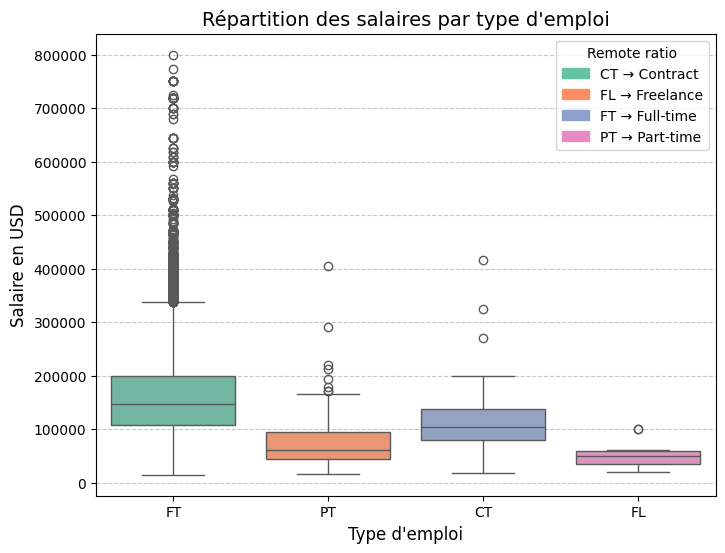

In [59]:
plt.figure(figsize=(8, 6))

# Liste des catégories uniques dans l'ordre
unique_employment_type = sorted(data_salary["employment_type"].unique())

# Palette de couleurs utilisée par sns.boxplot
colors = sns.color_palette("Set2", len(unique_employment_type))

sns.boxplot(x=data_salary["employment_type"], y=data_salary["salary_in_usd"], palette=colors)

plt.title("Répartition des salaires par type d'emploi", fontsize=14)
plt.xlabel("Type d'emploi", fontsize=12)
plt.ylabel("Salaire en USD", fontsize=12)
plt.grid(axis='y', linestyle="--", alpha=0.7)


# Créer la légende avec les vraies couleurs (conversion en str)
legend_patches = [
    mpatches.Patch(color=colors[i], label=f"{str(key)} → {dic_employment_type[str(key)]}")
    for i, key in enumerate(unique_employment_type) if str(key) in dic_employment_type
]

plt.legend(handles=legend_patches, title="Remote ratio", loc="upper right")

plt.show()

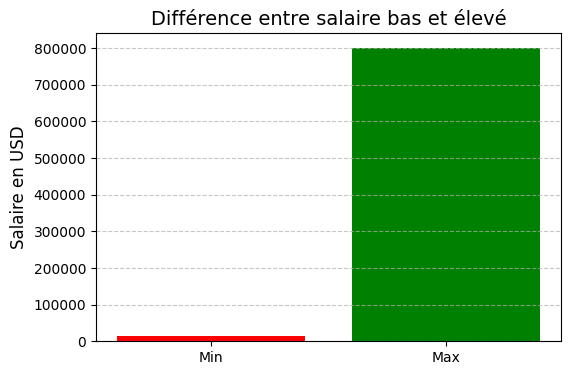

In [60]:
min_salary = data_salary["salary_in_usd"].min()
max_salary = data_salary["salary_in_usd"].max()

plt.figure(figsize=(6, 4))
plt.bar(["Min", "Max"], [min_salary, max_salary], color=['red', 'green'])

plt.title("Différence entre salaire bas et élevé", fontsize=14)
plt.ylabel("Salaire en USD", fontsize=12)
plt.grid(axis='y', linestyle="--", alpha=0.7)

plt.show()



Etude différence salaire par rapport remote ration work

C:\Users\Angelo Morningstar\AppData\Local\Temp\ipykernel_13972\3057892941.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=data_salary["remote_ratio"], y=data_salary["salary_in_usd"], palette=colors)


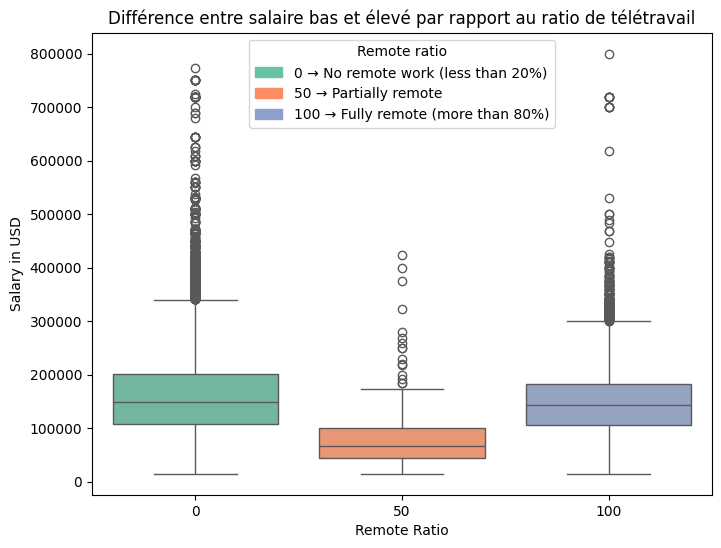

In [61]:

# Création de la figure
plt.figure(figsize=(8, 6))

# Liste des catégories uniques dans l'ordre
unique_remote_ratios = sorted(data_salary["remote_ratio"].unique())

# Palette de couleurs utilisée par sns.boxplot
colors = sns.color_palette("Set2", len(unique_remote_ratios))

# Tracer le boxplot avec la bonne palette
sns.boxplot(x=data_salary["remote_ratio"], y=data_salary["salary_in_usd"], palette=colors)

plt.title("Différence entre salaire bas et élevé par rapport au ratio de télétravail")
plt.xlabel("Remote Ratio")
plt.ylabel("Salary in USD")

# Créer la légende avec les vraies couleurs (conversion en str)
legend_patches = [
    mpatches.Patch(color=colors[i], label=f"{str(key)} → {dic_remote_ratio[str(key)]}")
    for i, key in enumerate(unique_remote_ratios) if str(key) in dic_remote_ratio
]

plt.legend(handles=legend_patches, title="Remote ratio", loc="upper center")

plt.show()



Etude différence salaire par taille d'entreprise 

C:\Users\Angelo Morningstar\AppData\Local\Temp\ipykernel_13972\2381533675.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=data_salary["company_size"], y=data_salary["salary_in_usd"], palette=colors)


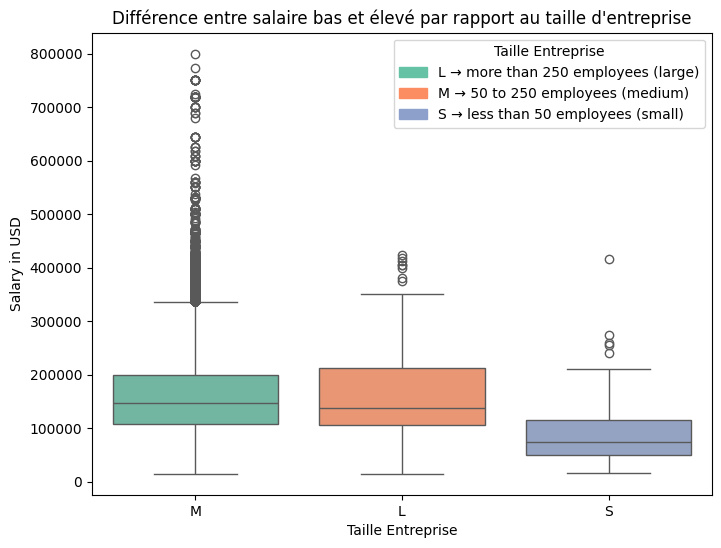

In [62]:

# Création de la figure
plt.figure(figsize=(8, 6))

# Liste des catégories uniques dans l'ordre
unique_company_size = sorted(data_salary["company_size"].unique())
# print(unique_company_size)

# Palette de couleurs utilisée par sns.boxplot
colors = sns.color_palette("Set2", len(unique_company_size))

# Tracer le boxplot avec la bonne palette
sns.boxplot(x=data_salary["company_size"], y=data_salary["salary_in_usd"], palette=colors)

plt.title("Différence entre salaire bas et élevé par rapport au taille d\'entreprise")
plt.xlabel("Taille Entreprise")
plt.ylabel("Salary in USD")

# Créer la légende avec les vraies couleurs (conversion en str)
legend_patches = [
    mpatches.Patch(color=colors[i], label=f"{str(key)} → {dic_company_size[str(key)]}")
    for i, key in enumerate(unique_company_size) if str(key) in dic_company_size
]

plt.legend(handles=legend_patches, title="Taille Entreprise", loc="upper right")

plt.show()




1.b. Evolution des salaires sur les années 

Etude en générale 

In [63]:
# Calcul du salaire moyen par année
salary_per_year_mean = data_salary.groupby("work_year")["salary_in_usd"].mean()
salary_per_year_median = data_salary.groupby("work_year")["salary_in_usd"].median()

print(salary_per_year_mean.head(5))
print(salary_per_year_median.head(5))


work_year
2020    102250.866667
2021     99922.073394
2022    134183.903556
2023    153700.755456
2024    159610.708556
Name: salary_in_usd, dtype: float64
work_year
2020     79833.0
2021     83872.0
2022    131300.0
2023    145000.0
2024    148960.0
Name: salary_in_usd, dtype: float64


Etude évolution globale : moyenne, médiane (en courbe continue)

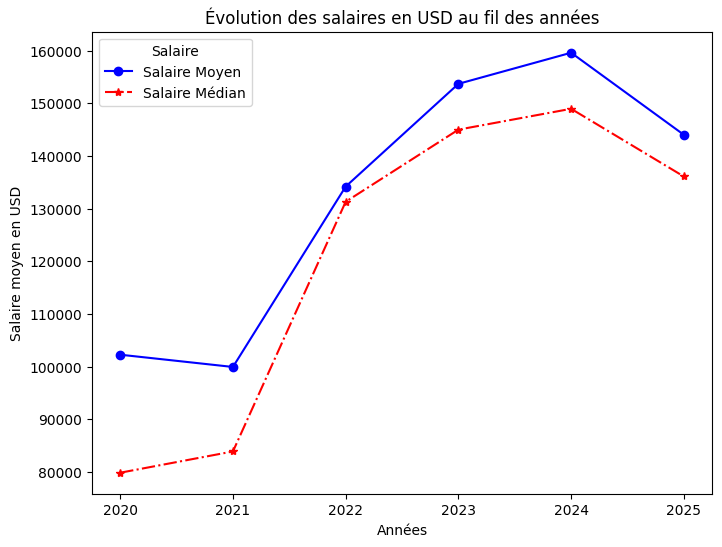

In [64]:


# Tracer l'évolution du salaire
plt.figure(figsize=(8,6))
plt.plot(salary_per_year_mean.index, salary_per_year_mean.values, marker="o", linestyle="-", color="b")
plt.plot(salary_per_year_median.index, salary_per_year_median.values, marker="*", linestyle="-.", color="r")

# Titres et labels
plt.title("Évolution des salaires en USD au fil des années")
plt.xlabel("Années")
plt.ylabel("Salaire moyen en USD")

# Créer la légende avec les bonnes couleurs
legend_lines = [
    mlines.Line2D([], [], color="blue", marker="o", linestyle="-", label="Salaire Moyen"),
    mlines.Line2D([], [], color="red", marker="*", linestyle="-.", label="Salaire Médian")
]


plt.legend(handles=legend_lines,title="Salaire",loc="upper left")

# Afficher le graphique
plt.show()


Etude évolution globale : moyenne, médiane (en discontinue - histogramme)

C:\Users\Angelo Morningstar\AppData\Local\Temp\ipykernel_13972\1446956399.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=salary_per_year_mean.index, y=salary_per_year_mean.values, palette="Blues")


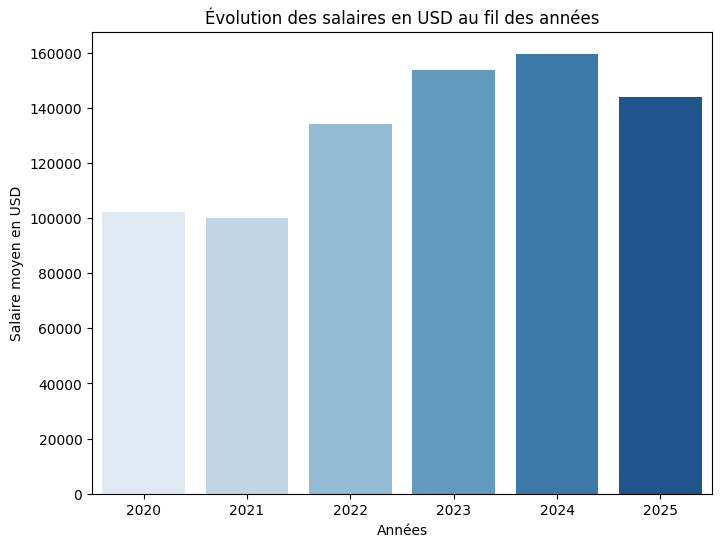

In [65]:
# Création de la figure
plt.figure(figsize=(8,6))

# Tracer un barplot avec les salaires moyens par année
sns.barplot(x=salary_per_year_mean.index, y=salary_per_year_mean.values, palette="Blues")

# Titres et labels
plt.title("Évolution des salaires en USD au fil des années")
plt.xlabel("Années")
plt.ylabel("Salaire moyen en USD")

plt.show()



Etude évolution par rapport au experience_level

In [66]:
salary_per_year_by_experience_level_mean = data_salary.groupby(["work_year","experience_level"])["salary_in_usd"].mean()
salary_per_year_by_experience_level_median = data_salary.groupby(["work_year","experience_level"])["salary_in_usd"].median()
print(salary_per_year_by_experience_level_mean.head(5))
print(salary_per_year_by_experience_level_median.head(5))


work_year  experience_level
2020       EN                   69840.666667
           EX                  179958.250000
           MI                   91870.935484
           SE                  138648.894737
2021       EN                   63463.065217
Name: salary_in_usd, dtype: float64
work_year  experience_level
2020       EN                   51321.0
           EX                  189916.5
           MI                   79833.0
           SE                  120000.0
2021       EN                   61915.5
Name: salary_in_usd, dtype: float64


Années uniques: [2025 2024 2022 2023 2020 2021]
Salaire min/max: 15000.0 / 800000.0
   work_year experience_level  salary_in_usd
0       2020         Director  179958.250000
1       2020           Expert  138648.894737
2       2020     Intermediate   91870.935484
3       2020           Junior   69840.666667
4       2021         Director  186128.000000
   work_year experience_level  salary_in_usd
0       2020         Director       189916.5
1       2020           Expert       120000.0
2       2020     Intermediate        79833.0
3       2020           Junior        51321.0
4       2021         Director       151833.5


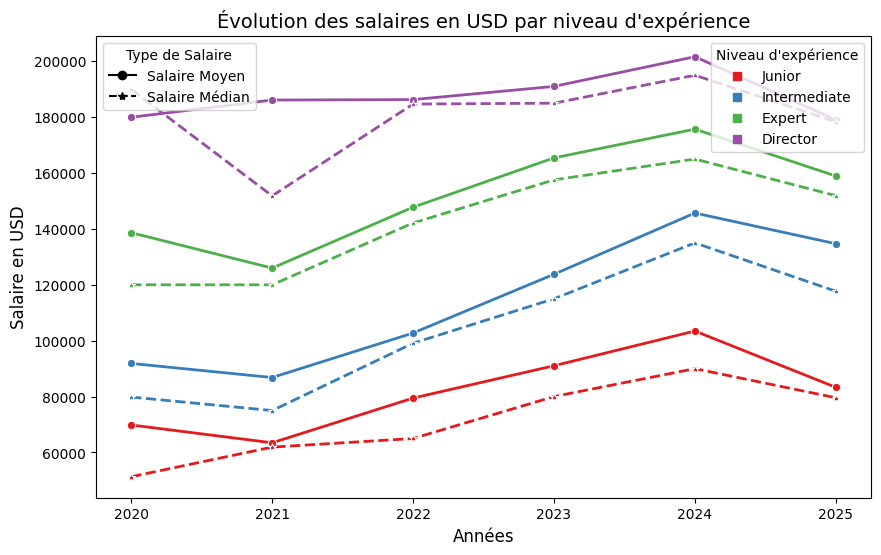

In [67]:

# Vérification et conversion des types
data_salary["work_year"] = data_salary["work_year"].astype(int)  # Années en entier
data_salary["salary_in_usd"] = data_salary["salary_in_usd"].astype(float)  # Salaires en float
data_salary["experience_level"] = data_salary["experience_level"].map(dic_experience_level)

# Vérifier les valeurs min/max pour détecter les erreurs
print("Années uniques:", data_salary["work_year"].unique())
print("Salaire min/max:", data_salary["salary_in_usd"].min(), "/", data_salary["salary_in_usd"].max())

# Calcul des salaires moyens et médians
salary_per_year_by_experience_level_mean = data_salary.groupby(["work_year", "experience_level"])["salary_in_usd"].mean().reset_index()
salary_per_year_by_experience_level_median = data_salary.groupby(["work_year", "experience_level"])["salary_in_usd"].median().reset_index()

print(salary_per_year_by_experience_level_mean.head())
print(salary_per_year_by_experience_level_median.head())

# Palette de couleurs cohérente
palette = sns.color_palette("Set1", n_colors=len(dic_experience_level))
experience_colors = {exp: color for exp, color in zip(dic_experience_level.values(), palette)}

# Tracer les moyennes et médianes
plt.figure(figsize=(10,6))

# Moyenne
sns.lineplot(
    data=salary_per_year_by_experience_level_mean,
    x="work_year", y="salary_in_usd", hue="experience_level",
    palette=experience_colors, marker="o", linestyle="-", linewidth=2
)

# Médiane (pointillés)
sns.lineplot(
    data=salary_per_year_by_experience_level_median,
    x="work_year", y="salary_in_usd", hue="experience_level",
    palette=experience_colors, marker="*", linestyle="--", linewidth=2
)

# Titres et labels
plt.title("Évolution des salaires en USD par niveau d'expérience", fontsize=14)
plt.xlabel("Années", fontsize=12)
plt.ylabel("Salaire en USD", fontsize=12)

# Vérification des axes
plt.xticks(sorted(data_salary["work_year"].unique()))  # Afficher toutes les années correctement

# Légende pour les types de salaire
legend_lines = [
    mlines.Line2D([], [], color="black", marker="o", linestyle="-", label="Salaire Moyen"),
    mlines.Line2D([], [], color="black", marker="*", linestyle="--", label="Salaire Médian")
]
first_legend = plt.legend(handles=legend_lines, title="Type de Salaire", loc="upper left")

# Légende pour les niveaux d'expérience
experience_legend_patches = [
    mlines.Line2D([], [], color=color, marker="s", linestyle="None", label=exp)
    for exp, color in experience_colors.items()
]
plt.legend(handles=experience_legend_patches, title="Niveau d'expérience", loc="upper right")

# Ajouter la légende du type de salaire en premier
plt.gca().add_artist(first_legend)

plt.show()


2. Analyse par localisation

2.1. Top Pays avec meilleur salaire 

In [68]:
grouped_employee_residence = data_salary["employee_residence"].unique()
grouped_company_location = data_salary["company_location"].unique()

print(f"employee_residence {len(grouped_employee_residence)} : {grouped_employee_residence}")
print(f"company_location {len(grouped_company_location)} : {grouped_company_location}")



employee_residence 93 : ['US' 'GB' 'CA' 'DE' 'LT' 'SK' 'FR' 'AU' 'AT' 'PH' 'AM' 'SG' 'LU' 'BR'
 'NL' 'IT' 'CO' 'CL' 'IN' 'PL' 'CY' 'ES' 'RW' 'NZ' 'CH' 'LV' 'IL' 'CZ'
 'IE' 'JP' 'PE' 'KR' 'ZA' 'EG' 'PR' 'LB' 'GR' 'AR' 'FI' 'MX' 'DK' 'NG'
 'BE' 'BG' 'EC' 'SV' 'CR' 'HU' 'PT' 'HR' 'KE' 'SE' 'UA' 'TR' 'PK' 'HN'
 'MT' 'RO' 'VE' 'BM' 'VN' 'RS' 'GE' 'AE' 'SA' 'OM' 'BA' 'EE' 'UG' 'SI'
 'MU' 'TH' 'QA' 'RU' 'TN' 'GH' 'AD' 'MD' 'NO' 'UZ' 'HK' 'CF' 'KW' 'IR'
 'AS' 'CN' 'BO' 'DO' 'ID' 'MY' 'DZ' 'IQ' 'JE']
company_location 86 : ['US' 'GB' 'CA' 'DE' 'LT' 'SK' 'FR' 'AU' 'AT' 'PH' 'AM' 'SG' 'LU' 'BR'
 'NL' 'IT' 'CO' 'CL' 'IN' 'PL' 'CY' 'ES' 'CD' 'NZ' 'CH' 'LV' 'IL' 'CZ'
 'IE' 'JP' 'PE' 'KR' 'ZA' 'EG' 'PR' 'LB' 'GR' 'AR' 'FI' 'MX' 'DK' 'NG'
 'BE' 'BG' 'EC' 'SV' 'CR' 'HU' 'PT' 'HR' 'KE' 'SE' 'UA' 'TR' 'PK' 'HN'
 'MT' 'RO' 'VE' 'DZ' 'AS' 'RS' 'AE' 'SA' 'OM' 'BA' 'EE' 'VN' 'GI' 'SI'
 'MU' 'RU' 'QA' 'GH' 'AD' 'NO' 'HK' 'CF' 'TH' 'IR' 'BS' 'ID' 'MY' 'IQ'
 'CN' 'MD']


In [69]:
# find top 5 pays location
grouped_salary_per_location = data_salary.groupby(["company_location"]).sum("salary_in_usd")
print (len(grouped_salary_per_location))
grouped_salary_per_location = grouped_salary_per_location.sort_values(by="salary_in_usd",ascending=False)
print( grouped_salary_per_location.head())


86
                  work_year       salary  salary_in_usd  remote_ratio
company_location                                                     
US                133644517  10832931752   1.081677e+10       1400850
CA                  5090059    344755309   3.379794e+08         68250
GB                  4320626    165933237   1.980881e+08         33350
AU                   489768     33704837   3.062889e+07          1850
DE                   465369     27578497   2.488860e+07          6300


In [70]:
# find top 5 employe_residence
grouped_salary_per_employe_residence = data_salary.groupby(["employee_residence"]).sum("salary_in_usd")
print (len(grouped_salary_per_employe_residence))
grouped_salary_per_employe_residence = grouped_salary_per_employe_residence.sort_values(by="salary_in_usd",ascending=False)
print( grouped_salary_per_employe_residence.head())


93
                    work_year       salary  salary_in_usd  remote_ratio
employee_residence                                                     
US                  133537347  10811283388   1.081241e+10       1396000
CA                    5086018    344642309   3.378761e+08         68200
GB                    4304452    165465837   1.975391e+08         32600
AU                     481677     30973837   3.033551e+07          1650
DE                     449192     23372097   2.463610e+07          5500
